<a href="https://colab.research.google.com/github/dilarabcde/acrima-glaucoma-detection/blob/main/03_ACRIMA_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

# Google Drive bağlantısı
drive.mount("/content/drive")

# Proje klasörü
ROOT = Path(
    "/content/drive/MyDrive/ACRIMA_Glaucoma_Project"
)

# Daha önce kaydettiğimiz veri bölmeleri
train_df = pd.read_csv(
    ROOT / "data/splits/train.csv"
)

val_df = pd.read_csv(
    ROOT / "data/splits/val.csv"
)

# GPU kontrolü
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Kullanılan cihaz:", device)

# Veri kümelerinin örtüşmediğini kontrol et
assert set(train_df["dosya_adi"]).isdisjoint(
    set(val_df["dosya_adi"])
)

print("Train/Validation ayrımı kontrol edildi.")


Mounted at /content/drive
Training: 493
Validation: 106
Kullanılan cihaz: cuda
Train/Validation ayrımı kontrol edildi.


In [2]:

import zipfile
from pathlib import Path

# Veri setinin bulunduğu ZIP dosyası
zip_path = ROOT / "Database.zip"

# Colab geçici diskindeki klasör
extract_path = Path("/content/acrima_data")
extract_path.mkdir(parents=True, exist_ok=True)

# ZIP dosyasını aç
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Görüntü klasörü
image_dir = extract_path / "Database" / "Images"

# JPG görüntülerini listele
image_files = [
    p for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() == ".jpg"
]

print("Görüntü klasörü:", image_dir.exists())
print("Toplam görüntü:", len(image_files))


Görüntü klasörü: True
Toplam görüntü: 705


In [3]:

from torchvision import transforms
import torch

torch.manual_seed(42)

# ImageNet normalizasyon değerleri
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Eğitim dönüşümleri
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Doğrulama dönüşümleri
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print("ResNet18 görüntü dönüşümleri hazır!")


ResNet18 görüntü dönüşümleri hazır!


In [4]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image

# ACRIMA veri seti sınıfı
class ACRIMADataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Görüntü adı ve sınıf bilgisi
        dosya_adi = self.dataframe.iloc[index]["dosya_adi"]
        sinif = self.dataframe.iloc[index]["sinif"]

        # Görüntüyü RGB olarak aç
        with Image.open(self.image_dir / dosya_adi) as img:
            image = img.convert("RGB")

        # Dönüşümleri uygula
        if self.transform:
            image = self.transform(image)

        # Normal = 0, Glokom = 1
        label = 1 if sinif == "Glokom" else 0

        return image, label


# Dataset oluştur
train_dataset = ACRIMADataset(
    train_df, image_dir, train_transform
)

val_dataset = ACRIMADataset(
    val_df, image_dir, val_transform
)

# DataLoader oluştur
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

# Kontrol
print("Training Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Training Batch:", len(train_loader))
print("Validation Batch:", len(val_loader))

# Bir batch'in boyutunu kontrol et
goruntuler, etiketler = next(iter(train_loader))

print("Görüntü boyutu:", goruntuler.shape)
print("Etiket boyutu:", etiketler.shape)


Training Dataset: 493
Validation Dataset: 106
Training Batch: 31
Validation Batch: 7
Görüntü boyutu: torch.Size([16, 3, 224, 224])
Etiket boyutu: torch.Size([16])


In [5]:

import torch
import torch.nn as nn
from torchvision import models

# Önceden eğitilmiş ResNet18'i yükle
weights = models.ResNet18_Weights.DEFAULT

resnet18 = models.resnet18(weights=weights)

# Önceden eğitilmiş katmanları dondur
for param in resnet18.parameters():
    param.requires_grad = False

# Son sınıflandırma katmanını değiştir
num_features = resnet18.fc.in_features

resnet18.fc = nn.Linear(num_features, 2)

# Modeli GPU'ya taşı
resnet18 = resnet18.to(device)

# Parametre sayılarını hesapla
total_params = sum(
    p.numel() for p in resnet18.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet18.parameters()
    if p.requires_grad
)

print("Toplam parametre:", total_params)
print("Eğitilebilir parametre:", trainable_params)
print("Kullanılan cihaz:", device)

# Modelin çıktı boyutunu kontrol et
resnet18.eval()

with torch.no_grad():
    cikti = resnet18(goruntuler.to(device))

print("Giriş boyutu:", goruntuler.shape)
print("Çıkış boyutu:", cikti.shape)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Toplam parametre: 11177538
Eğitilebilir parametre: 1026
Kullanılan cihaz: cuda
Giriş boyutu: torch.Size([16, 3, 224, 224])
Çıkış boyutu: torch.Size([16, 2])


In [6]:

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score

# Eğitim ayarları
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet18.fc.parameters(),
    lr=0.001
)

epochs = 10

resnet_train_losses = []
resnet_val_f1_scores = []

best_f1 = -1.0
best_epoch = 0

# Model kayıt klasörü
model_dir = ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Eğitim döngüsü
for epoch in range(epochs):

    # Önceden eğitilmiş katmanları eval modunda tut
    # Böylece BatchNorm istatistikleri değişmez
    resnet18.eval()
    resnet18.fc.train()

    toplam_loss = 0

    # TRAINING
    for goruntuler, etiketler in train_loader:

        goruntuler = goruntuler.to(device)
        etiketler = etiketler.to(device)

        optimizer.zero_grad()

        cikti = resnet18(goruntuler)
        loss = criterion(cikti, etiketler)

        loss.backward()
        optimizer.step()

        toplam_loss += loss.item() * goruntuler.size(0)

    train_loss = toplam_loss / len(train_dataset)

    # VALIDATION
    resnet18.eval()

    gercek = []
    tahmin = []

    with torch.no_grad():
        for goruntuler, etiketler in val_loader:

            goruntuler = goruntuler.to(device)

            cikti = resnet18(goruntuler)
            predicted = torch.argmax(cikti, dim=1)

            gercek.extend(etiketler.numpy())
            tahmin.extend(predicted.cpu().numpy())

    macro_f1 = f1_score(
        gercek,
        tahmin,
        average="macro",
        zero_division=0
    )

    resnet_train_losses.append(train_loss)
    resnet_val_f1_scores.append(macro_f1)

    # En iyi model ağırlıklarını kaydet
    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_epoch = epoch + 1

        torch.save(
            resnet18.state_dict(),
            model_dir / "resnet18_best.pth"
        )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Macro F1: {macro_f1:.4f}"
    )

print("\nResNet18 eğitimi tamamlandı!")
print("En iyi epoch:", best_epoch)
print(f"En iyi Validation Macro F1: {best_f1:.4f}")


Epoch 1/10 | Train Loss: 0.6557 | Validation Macro F1: 0.6884
Epoch 2/10 | Train Loss: 0.4989 | Validation Macro F1: 0.7358
Epoch 3/10 | Train Loss: 0.4306 | Validation Macro F1: 0.7807
Epoch 4/10 | Train Loss: 0.4140 | Validation Macro F1: 0.7733
Epoch 5/10 | Train Loss: 0.3456 | Validation Macro F1: 0.8188
Epoch 6/10 | Train Loss: 0.3133 | Validation Macro F1: 0.8089
Epoch 7/10 | Train Loss: 0.3249 | Validation Macro F1: 0.7733
Epoch 8/10 | Train Loss: 0.3086 | Validation Macro F1: 0.8486
Epoch 9/10 | Train Loss: 0.2806 | Validation Macro F1: 0.8486
Epoch 10/10 | Train Loss: 0.2714 | Validation Macro F1: 0.7828

ResNet18 eğitimi tamamlandı!
En iyi epoch: 8
En iyi Validation Macro F1: 0.8486


ResNet18 Validation Accuracy: 0.8491
ResNet18 Validation Macro F1: 0.8486
Balanced Accuracy: 0.8565

Classification Report:
              precision    recall  f1-score   support

      Normal     0.7778    0.9130    0.8400        46
      Glokom     0.9231    0.8000    0.8571        60

    accuracy                         0.8491       106
   macro avg     0.8504    0.8565    0.8486       106
weighted avg     0.8600    0.8491    0.8497       106



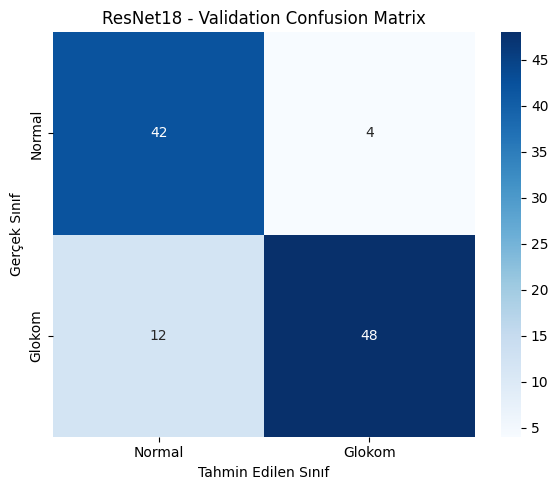

In [7]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# En iyi ResNet18 ağırlıklarını yükle
resnet18.load_state_dict(
    torch.load(
        ROOT / "models" / "resnet18_best.pth",
        map_location=device,
        weights_only=True
    )
)

resnet18.eval()

resnet_gercek = []
resnet_tahmin = []

# Validation değerlendirmesi
with torch.no_grad():
    for goruntuler, etiketler in val_loader:

        goruntuler = goruntuler.to(device)

        cikti = resnet18(goruntuler)
        predicted = torch.argmax(cikti, dim=1)

        resnet_gercek.extend(etiketler.numpy())
        resnet_tahmin.extend(predicted.cpu().numpy())

# Performans ölçütleri
resnet_accuracy = accuracy_score(
    resnet_gercek, resnet_tahmin
)

resnet_macro_f1 = f1_score(
    resnet_gercek,
    resnet_tahmin,
    average="macro"
)

resnet_balanced_acc = balanced_accuracy_score(
    resnet_gercek, resnet_tahmin
)

print("ResNet18 Validation Accuracy:", round(resnet_accuracy, 4))
print("ResNet18 Validation Macro F1:", round(resnet_macro_f1, 4))
print("Balanced Accuracy:", round(resnet_balanced_acc, 4))

print("\nClassification Report:")
print(classification_report(
    resnet_gercek,
    resnet_tahmin,
    target_names=["Normal", "Glokom"],
    digits=4
))

# Confusion Matrix
resnet_cm = confusion_matrix(
    resnet_gercek,
    resnet_tahmin,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    resnet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("ResNet18 - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.tight_layout()
plt.show()


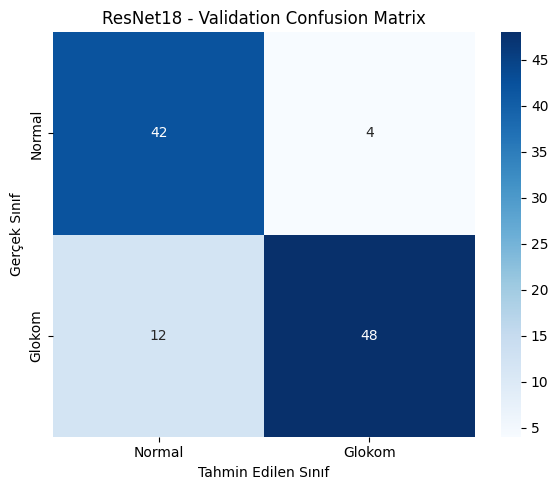

ResNet18 sonuçları kaydedildi!
                        model veri_kumesi  accuracy  macro_f1  \
0  ResNet18_FeatureExtraction  validation  0.849057  0.848571   

   balanced_accuracy  seed  best_epoch  
0           0.856522    42           8  


In [8]:

import pandas as pd

# Sonuç tablosu
resnet_sonuclar = pd.DataFrame([{
    "model": "ResNet18_FeatureExtraction",
    "veri_kumesi": "validation",
    "accuracy": resnet_accuracy,
    "macro_f1": resnet_macro_f1,
    "balanced_accuracy": resnet_balanced_acc,
    "seed": 42,
    "best_epoch": best_epoch
}])

# Klasörleri kontrol et
(ROOT / "results").mkdir(parents=True, exist_ok=True)
(ROOT / "figures").mkdir(parents=True, exist_ok=True)

# Sonuçları kaydet
resnet_sonuclar.to_csv(
    ROOT / "results" / "resnet18_results.csv",
    index=False
)

# Eğitim geçmişini kaydet
resnet_history = pd.DataFrame({
    "epoch": range(1, len(resnet_train_losses) + 1),
    "train_loss": resnet_train_losses,
    "val_macro_f1": resnet_val_f1_scores
})

resnet_history.to_csv(
    ROOT / "results" / "resnet18_history.csv",
    index=False
)

# Hata matrisini kaydet
plt.figure(figsize=(6, 5))

sns.heatmap(
    resnet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("ResNet18 - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig(
    ROOT / "figures" / "resnet18_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("ResNet18 sonuçları kaydedildi!")
print(resnet_sonuclar)


In [9]:

import copy
import torch
import torch.nn as nn
import torch.optim as optim

# Önceki ResNet18 modelinin ayrı bir kopyasını oluştur
resnet_finetune = copy.deepcopy(resnet18)

# En iyi Feature Extraction ağırlıklarını yükle
resnet_finetune.load_state_dict(
    torch.load(
        ROOT / "models" / "resnet18_best.pth",
        map_location=device,
        weights_only=True
    )
)

# Önce bütün katmanları dondur
for param in resnet_finetune.parameters():
    param.requires_grad = False

# Son convolution bloğunu eğitime aç
for param in resnet_finetune.layer4.parameters():
    param.requires_grad = True

# Son sınıflandırma katmanını eğitime aç
for param in resnet_finetune.fc.parameters():
    param.requires_grad = True

resnet_finetune = resnet_finetune.to(device)

# Farklı katmanlara farklı öğrenme hızları
finetune_optimizer = optim.Adam([
    {
        "params": resnet_finetune.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": resnet_finetune.fc.parameters(),
        "lr": 0.0001
    }
])

finetune_criterion = nn.CrossEntropyLoss()
finetune_epochs = 10

# Eğitilebilir parametreleri hesapla
trainable_params = sum(
    p.numel()
    for p in resnet_finetune.parameters()
    if p.requires_grad
)

print("Fine-Tuning modeli hazır!")
print("Eğitilebilir parametre:", trainable_params)
print("Epoch:", finetune_epochs)
print("Kullanılan cihaz:", device)


Fine-Tuning modeli hazır!
Eğitilebilir parametre: 8394754
Epoch: 10
Kullanılan cihaz: cuda


In [10]:

from sklearn.metrics import f1_score
import torch

# Eğitim sonuçlarını sakla
finetune_train_losses = []
finetune_val_f1_scores = []

finetune_best_f1 = -1.0
finetune_best_epoch = 0

model_dir = ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Fine-Tuning eğitim döngüsü
for epoch in range(finetune_epochs):

    # Modeli eğitim moduna al
    resnet_finetune.train()

    # Dondurulmuş katmanların BatchNorm
    # istatistiklerini sabit tut
    for name, module in resnet_finetune.named_modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()

    toplam_loss = 0.0

    # TRAINING
    for goruntuler, etiketler in train_loader:

        goruntuler = goruntuler.to(device)
        etiketler = etiketler.to(device)

        finetune_optimizer.zero_grad()

        # Forward
        cikti = resnet_finetune(goruntuler)

        # Loss
        loss = finetune_criterion(cikti, etiketler)

        # Backward
        loss.backward()

        # Ağırlıkları güncelle
        finetune_optimizer.step()

        toplam_loss += loss.item() * goruntuler.size(0)

    train_loss = toplam_loss / len(train_dataset)

    # VALIDATION
    resnet_finetune.eval()

    gercek = []
    tahmin = []

    with torch.no_grad():
        for goruntuler, etiketler in val_loader:

            goruntuler = goruntuler.to(device)

            cikti = resnet_finetune(goruntuler)
            predicted = torch.argmax(cikti, dim=1)

            gercek.extend(etiketler.numpy())
            tahmin.extend(predicted.cpu().numpy())

    macro_f1 = f1_score(
        gercek,
        tahmin,
        average="macro",
        zero_division=0
    )

    finetune_train_losses.append(train_loss)
    finetune_val_f1_scores.append(macro_f1)

    # En iyi modeli kaydet
    if macro_f1 > finetune_best_f1:

        finetune_best_f1 = macro_f1
        finetune_best_epoch = epoch + 1

        torch.save(
            resnet_finetune.state_dict(),
            model_dir / "resnet18_finetuned_best.pth"
        )

    print(
        f"Epoch {epoch+1}/{finetune_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Macro F1: {macro_f1:.4f}"
    )

print("\nResNet18 Fine-Tuning tamamlandı!")
print("En iyi epoch:", finetune_best_epoch)
print(
    f"En iyi Validation Macro F1: "
    f"{finetune_best_f1:.4f}"
)


Epoch 1/10 | Train Loss: 0.2780 | Validation Macro F1: 0.8579
Epoch 2/10 | Train Loss: 0.2112 | Validation Macro F1: 0.8672
Epoch 3/10 | Train Loss: 0.1451 | Validation Macro F1: 0.8760
Epoch 4/10 | Train Loss: 0.1218 | Validation Macro F1: 0.8946
Epoch 5/10 | Train Loss: 0.0922 | Validation Macro F1: 0.8946
Epoch 6/10 | Train Loss: 0.0879 | Validation Macro F1: 0.8853
Epoch 7/10 | Train Loss: 0.0835 | Validation Macro F1: 0.9040
Epoch 8/10 | Train Loss: 0.0369 | Validation Macro F1: 0.8579
Epoch 9/10 | Train Loss: 0.0489 | Validation Macro F1: 0.8946
Epoch 10/10 | Train Loss: 0.0337 | Validation Macro F1: 0.8579

ResNet18 Fine-Tuning tamamlandı!
En iyi epoch: 7
En iyi Validation Macro F1: 0.9040


Fine-Tuning Accuracy: 0.9057
Fine-Tuning Macro F1: 0.904
Balanced Accuracy: 0.904

Classification Report:
              precision    recall  f1-score   support

      Normal     0.8913    0.8913    0.8913        46
      Glokom     0.9167    0.9167    0.9167        60

    accuracy                         0.9057       106
   macro avg     0.9040    0.9040    0.9040       106
weighted avg     0.9057    0.9057    0.9057       106



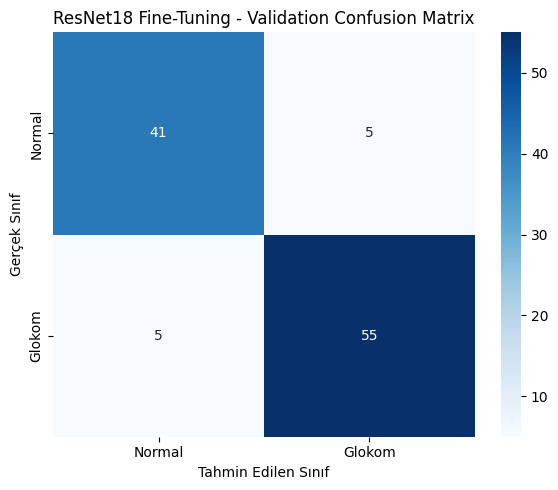

In [11]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# En iyi Fine-Tuning modelini yükle
resnet_finetune.load_state_dict(
    torch.load(
        ROOT / "models" / "resnet18_finetuned_best.pth",
        map_location=device,
        weights_only=True
    )
)

resnet_finetune.eval()

finetune_gercek = []
finetune_tahmin = []

# Validation değerlendirmesi
with torch.no_grad():
    for goruntuler, etiketler in val_loader:

        goruntuler = goruntuler.to(device)

        cikti = resnet_finetune(goruntuler)
        predicted = torch.argmax(cikti, dim=1)

        finetune_gercek.extend(etiketler.numpy())
        finetune_tahmin.extend(predicted.cpu().numpy())

# Performans metrikleri
finetune_accuracy = accuracy_score(
    finetune_gercek, finetune_tahmin
)

finetune_macro_f1 = f1_score(
    finetune_gercek,
    finetune_tahmin,
    average="macro",
    zero_division=0
)

finetune_balanced_acc = balanced_accuracy_score(
    finetune_gercek, finetune_tahmin
)

print("Fine-Tuning Accuracy:", round(finetune_accuracy, 4))
print("Fine-Tuning Macro F1:", round(finetune_macro_f1, 4))
print("Balanced Accuracy:", round(finetune_balanced_acc, 4))

print("\nClassification Report:")
print(classification_report(
    finetune_gercek,
    finetune_tahmin,
    target_names=["Normal", "Glokom"],
    digits=4
))

# Confusion Matrix
finetune_cm = confusion_matrix(
    finetune_gercek,
    finetune_tahmin,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    finetune_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("ResNet18 Fine-Tuning - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.show()


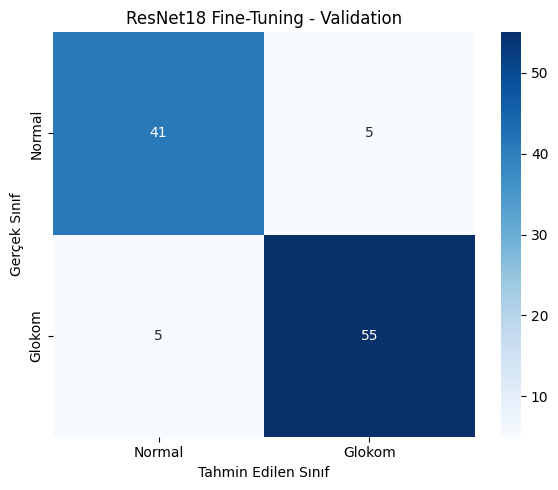

Fine-Tuning sonuçları kaydedildi!
                 model veri_kumesi  accuracy  macro_f1  balanced_accuracy  \
0  ResNet18_FineTuning  validation   0.90566  0.903986           0.903986   

   seed  best_epoch  
0    42           7  


In [12]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import balanced_accuracy_score

# Sonuç tablosu
finetune_sonuclar = pd.DataFrame([{
    "model": "ResNet18_FineTuning",
    "veri_kumesi": "validation",
    "accuracy": finetune_accuracy,
    "macro_f1": finetune_macro_f1,
    "balanced_accuracy": finetune_balanced_acc,
    "seed": 42,
    "best_epoch": finetune_best_epoch
}])

# Sonuçları kaydet
finetune_sonuclar.to_csv(
    ROOT / "results" / "resnet18_finetuned_results.csv",
    index=False
)

# Eğitim geçmişini kaydet
finetune_history = pd.DataFrame({
    "epoch": range(1, len(finetune_train_losses) + 1),
    "train_loss": finetune_train_losses,
    "val_macro_f1": finetune_val_f1_scores
})

finetune_history.to_csv(
    ROOT / "results" / "resnet18_finetuned_history.csv",
    index=False
)

# Confusion Matrix grafiği
plt.figure(figsize=(6, 5))

sns.heatmap(
    finetune_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("ResNet18 Fine-Tuning - Validation")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()

plt.savefig(
    ROOT / "figures" / "resnet18_finetuned_cm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Fine-Tuning sonuçları kaydedildi!")
print(finetune_sonuclar)


In [13]:

import pandas as pd

# Beş modelin kayıtlı sonuçları
dosyalar = [
    "baseline_results.csv",
    "simple_cnn_results.csv",
    "deep_cnn_results.csv",
    "resnet18_results.csv",
    "resnet18_finetuned_results.csv"
]

# Sonuç dosyalarını oku
tablolar = []

for dosya in dosyalar:
    df = pd.read_csv(ROOT / "results" / dosya)
    tablolar.append(df)

# Tüm sonuçları birleştir
karsilastirma = pd.concat(
    tablolar,
    ignore_index=True
)

# Macro F1'e göre sırala
karsilastirma = karsilastirma.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

# Karşılaştırma tablosunu kaydet
karsilastirma.to_csv(
    ROOT / "results" / "model_comparison.csv",
    index=False
)

# Tabloyu göster
print("ACRIMA - Model Karşılaştırması")
print(
    karsilastirma[
        ["model", "accuracy", "macro_f1",
         "balanced_accuracy"]
    ].round(4)
)

print("\nKarşılaştırma tablosu kaydedildi!")


ACRIMA - Model Karşılaştırması
                        model  accuracy  macro_f1  balanced_accuracy
0                     DeepCNN    0.9434    0.9429             0.9475
1         ResNet18_FineTuning    0.9057    0.9040             0.9040
2                   SimpleCNN    0.8585    0.8527             0.8471
3  ResNet18_FeatureExtraction    0.8491    0.8486             0.8565
4                     HOG_SVM    0.8113    0.8057             0.8029

Karşılaştırma tablosu kaydedildi!


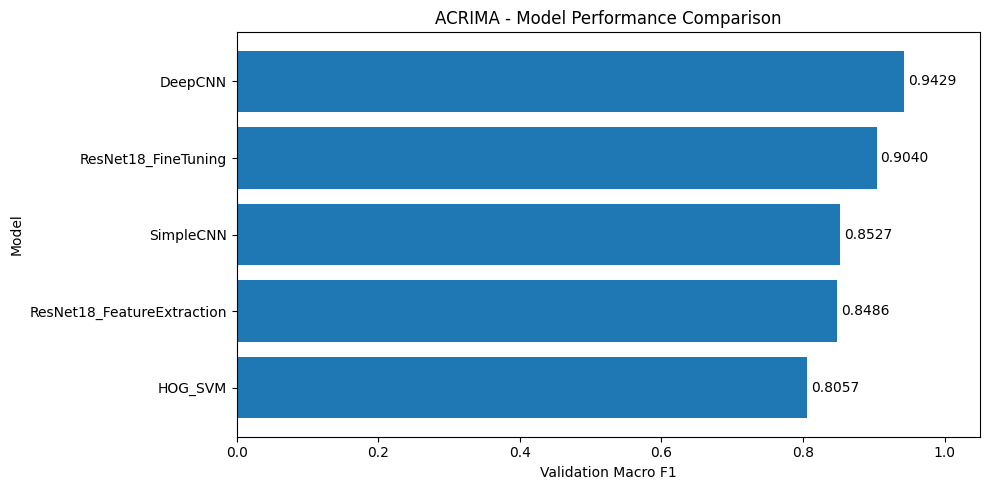

Model karşılaştırma grafiği kaydedildi!


In [14]:

import matplotlib.pyplot as plt

# Modelleri Macro F1'e göre sırala
grafik_df = karsilastirma.sort_values(
    by="macro_f1",
    ascending=True
)

plt.figure(figsize=(10, 5))

# Yatay çubuk grafik
plt.barh(
    grafik_df["model"],
    grafik_df["macro_f1"]
)

# Değerleri çubukların yanına yaz
for i, deger in enumerate(grafik_df["macro_f1"]):
    plt.text(
        deger + 0.005,
        i,
        f"{deger:.4f}",
        va="center"
    )

plt.xlabel("Validation Macro F1")
plt.ylabel("Model")
plt.title("ACRIMA - Model Performance Comparison")
plt.xlim(0, 1.05)

plt.tight_layout()

# Grafiği Drive'a kaydet
plt.savefig(
    ROOT / "figures" / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model karşılaştırma grafiği kaydedildi!")


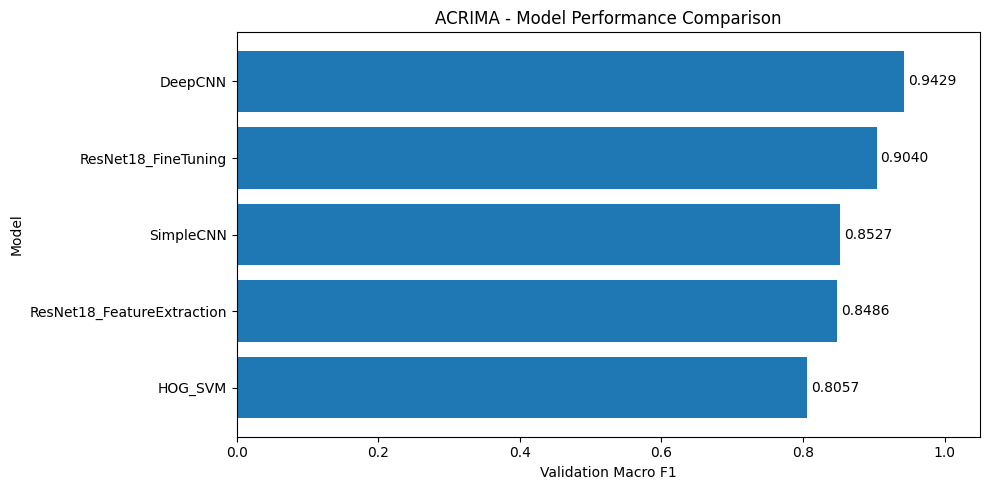

Model karşılaştırma grafiği kaydedildi!


In [15]:

import matplotlib.pyplot as plt

# Modelleri Macro F1'e göre sırala
grafik_df = karsilastirma.sort_values(
    by="macro_f1",
    ascending=True
)

plt.figure(figsize=(10, 5))

# Yatay çubuk grafik
plt.barh(
    grafik_df["model"],
    grafik_df["macro_f1"]
)

# Değerleri çubukların yanına yaz
for i, deger in enumerate(grafik_df["macro_f1"]):
    plt.text(
        deger + 0.005,
        i,
        f"{deger:.4f}",
        va="center"
    )

plt.xlabel("Validation Macro F1")
plt.ylabel("Model")
plt.title("ACRIMA - Model Performance Comparison")
plt.xlim(0, 1.05)

plt.tight_layout()

# Grafiği Drive'a kaydet
plt.savefig(
    ROOT / "figures" / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model karşılaştırma grafiği kaydedildi!")


In [16]:

import pandas as pd
import hashlib

# Kaydedilmiş veri bölmelerini oku
train_df = pd.read_csv(ROOT / "data/splits/train.csv")
val_df = pd.read_csv(ROOT / "data/splits/val.csv")
test_df = pd.read_csv(ROOT / "data/splits/test.csv")

# Dosya adlarını karşılaştır
train_set = set(train_df["dosya_adi"])
val_set = set(val_df["dosya_adi"])
test_set = set(test_df["dosya_adi"])

print("Train-Val ortak:", len(train_set & val_set))
print("Train-Test ortak:", len(train_set & test_set))
print("Val-Test ortak:", len(val_set & test_set))

# Görüntülerin SHA256 hash değerlerini hesapla
def hash_hesapla(dosya_adi):
    path = image_dir / dosya_adi

    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

train_hash = set(map(hash_hesapla, train_set))
val_hash = set(map(hash_hesapla, val_set))
test_hash = set(map(hash_hesapla, test_set))

print("\nGörüntü içeriği kontrolü:")
print("Train-Val aynı içerik:", len(train_hash & val_hash))
print("Train-Test aynı içerik:", len(train_hash & test_hash))
print("Val-Test aynı içerik:", len(val_hash & test_hash))

# Genel kontrol
assert len(train_set | val_set | test_set) == 705
assert not (train_hash & val_hash)
assert not (train_hash & test_hash)
assert not (val_hash & test_hash)

print("\nDosya ve birebir içerik kontrolü başarılı!")


Train-Val ortak: 0
Train-Test ortak: 0
Val-Test ortak: 0

Görüntü içeriği kontrolü:
Train-Val aynı içerik: 0
Train-Test aynı içerik: 0
Val-Test aynı içerik: 0

Dosya ve birebir içerik kontrolü başarılı!


In [17]:

import pandas as pd

# Veri bölmesi kontrol sonuçları
leakage_results = pd.DataFrame([
    {
        "kontrol": "Train-Val",
        "ortak_dosya": len(train_set & val_set),
        "ortak_hash": len(train_hash & val_hash)
    },
    {
        "kontrol": "Train-Test",
        "ortak_dosya": len(train_set & test_set),
        "ortak_hash": len(train_hash & test_hash)
    },
    {
        "kontrol": "Val-Test",
        "ortak_dosya": len(val_set & test_set),
        "ortak_hash": len(val_hash & test_hash)
    }
])

# Raporu kaydet
leakage_results.to_csv(
    ROOT / "results" / "data_leakage_check.csv",
    index=False
)

print("Data Leakage kontrol raporu kaydedildi!")
print(leakage_results)


Data Leakage kontrol raporu kaydedildi!
      kontrol  ortak_dosya  ortak_hash
0   Train-Val            0           0
1  Train-Test            0           0
2    Val-Test            0           0


In [18]:

from PIL import Image
import numpy as np
from scipy.fft import dctn
import pandas as pd

# Görüntünün perceptual hash değerini hesapla
def phash_hesapla(dosya_adi):
    with Image.open(image_dir / dosya_adi) as img:
        img = img.convert("L").resize((32, 32))
        piksel = np.asarray(img, dtype=np.float32)

    # Discrete Cosine Transform
    dct = dctn(piksel, norm="ortho")

    # Düşük frekans bileşenlerini al
    blok = dct[:8, :8].copy()

    # DC bileşenini medyan hesabından çıkar
    medyan = np.median(blok.flatten()[1:])

    return blok > medyan


# İki hash arasındaki Hamming Distance
def hash_uzakligi(hash1, hash2):
    return int(np.count_nonzero(hash1 != hash2))


# Görüntülerin hash değerlerini hesapla
tum_dosyalar = sorted(
    train_set | val_set | test_set
)

hashler = {
    dosya: phash_hesapla(dosya)
    for dosya in tum_dosyalar
}

print("pHash hesaplanan görüntü:", len(hashler))

# Farklı bölmeler arasındaki benzer çiftleri bul
bolmeler = {
    "train": sorted(train_set),
    "validation": sorted(val_set),
    "test": sorted(test_set)
}

benzer_ciftler = []

bolme_ciftleri = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for bolme1, bolme2 in bolme_ciftleri:
    for dosya1 in bolmeler[bolme1]:
        for dosya2 in bolmeler[bolme2]:

            uzaklik = hash_uzakligi(
                hashler[dosya1],
                hashler[dosya2]
            )

            if uzaklik <= 10:
                benzer_ciftler.append({
                    "dosya1": dosya1,
                    "dosya2": dosya2,
                    "bolme1": bolme1,
                    "bolme2": bolme2,
                    "phash_uzakligi": uzaklik
                })

benzer_df = pd.DataFrame(
    benzer_ciftler,
    columns=[
        "dosya1", "dosya2",
        "bolme1", "bolme2",
        "phash_uzakligi"
    ]
)

benzer_df = benzer_df.sort_values(
    by="phash_uzakligi"
).reset_index(drop=True)

print("Şüpheli benzer çift sayısı:", len(benzer_df))
print("\nİlk 10 şüpheli çift:")
print(benzer_df.head(10))


pHash hesaplanan görüntü: 705
Şüpheli benzer çift sayısı: 21

İlk 10 şüpheli çift:
               dosya1              dosya2 bolme1      bolme2  phash_uzakligi
0  Im503_g_ACRIMA.jpg  Im705_g_ACRIMA.jpg  train        test               8
1    Im046_ACRIMA.jpg  Im371_g_ACRIMA.jpg  train  validation              10
2  Im313_g_ACRIMA.jpg  Im527_g_ACRIMA.jpg  train  validation              10
3    Im055_ACRIMA.jpg    Im275_ACRIMA.jpg  train  validation              10
4  Im505_g_ACRIMA.jpg  Im561_g_ACRIMA.jpg  train  validation              10
5  Im557_g_ACRIMA.jpg    Im016_ACRIMA.jpg  train  validation              10
6    Im082_ACRIMA.jpg    Im086_ACRIMA.jpg  train        test              10
7  Im348_g_ACRIMA.jpg    Im092_ACRIMA.jpg  train  validation              10
8    Im176_ACRIMA.jpg    Im086_ACRIMA.jpg  train        test              10
9    Im199_ACRIMA.jpg    Im048_ACRIMA.jpg  train        test              10


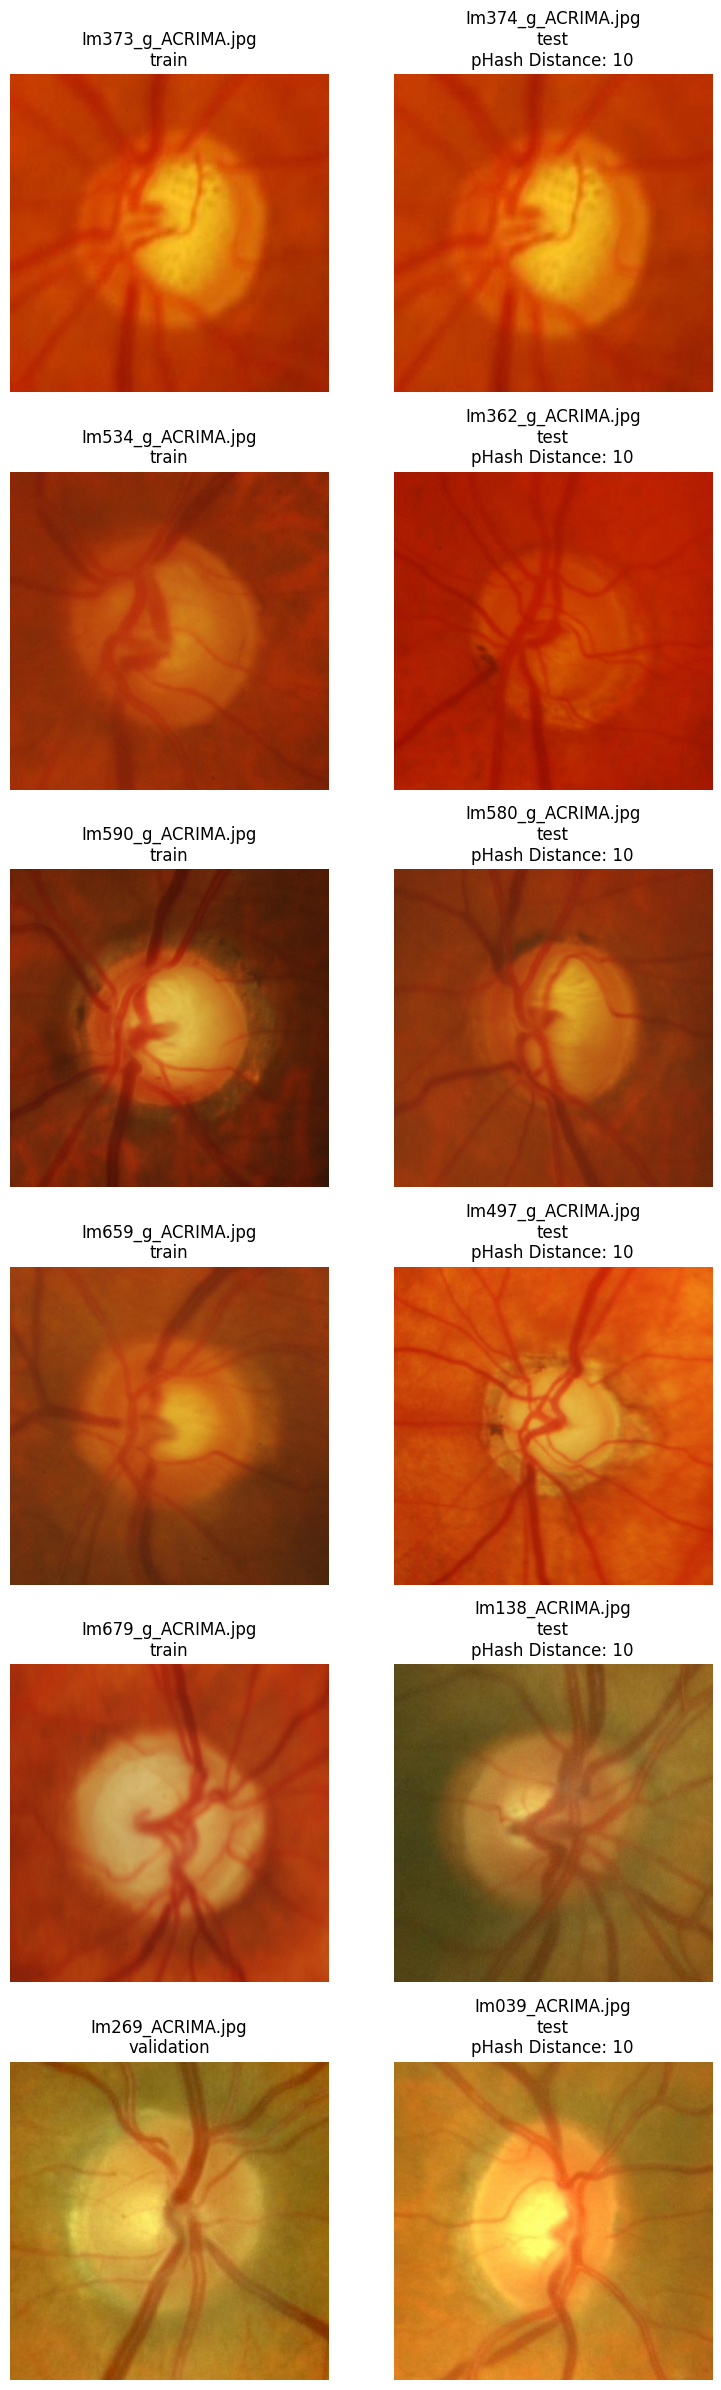

Şüpheli görüntü çiftleri görselleştirildi!


In [22]:

import matplotlib.pyplot as plt
from PIL import Image

# En düşük pHash uzaklığına sahip ilk 5 çift
ilk_ciftler = benzer_df.iloc[15:21]

fig, axes = plt.subplots(
    len(ilk_ciftler), 2,
    figsize=(8, 4 * len(ilk_ciftler))
)

for i, (_, satir) in enumerate(ilk_ciftler.iterrows()):

    dosya1 = satir["dosya1"]
    dosya2 = satir["dosya2"]

    with Image.open(image_dir / dosya1) as img:
        image1 = img.convert("RGB").copy()

    with Image.open(image_dir / dosya2) as img:
        image2 = img.convert("RGB").copy()

    axes[i, 0].imshow(image1)
    axes[i, 0].set_title(
        f"{dosya1}\n{satir['bolme1']}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image2)
    axes[i, 1].set_title(
        f"{dosya2}\n{satir['bolme2']}\n"
        f"pHash Distance: {satir['phash_uzakligi']}"
    )
    axes[i, 1].axis("off")

plt.tight_layout()

plt.savefig(
    ROOT / "figures" / "suspicious_image_pairs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Şüpheli görüntü çiftleri görselleştirildi!")


In [23]:
import numpy as np
from PIL import Image
from skimage.metrics import structural_similarity as ssim

dosya1 = "Im373_g_ACRIMA.jpg"
dosya2 = "Im374_g_ACRIMA.jpg"

def goruntu_oku(ad):
    with Image.open(image_dir / ad) as img:
        return np.array(
            img.convert("L").resize((256, 256))
        )

img1 = goruntu_oku(dosya1)
img2 = goruntu_oku(dosya2)

skor = ssim(img1, img2, data_range=255)

print("SSIM:", round(skor, 4))

SSIM: 0.8832


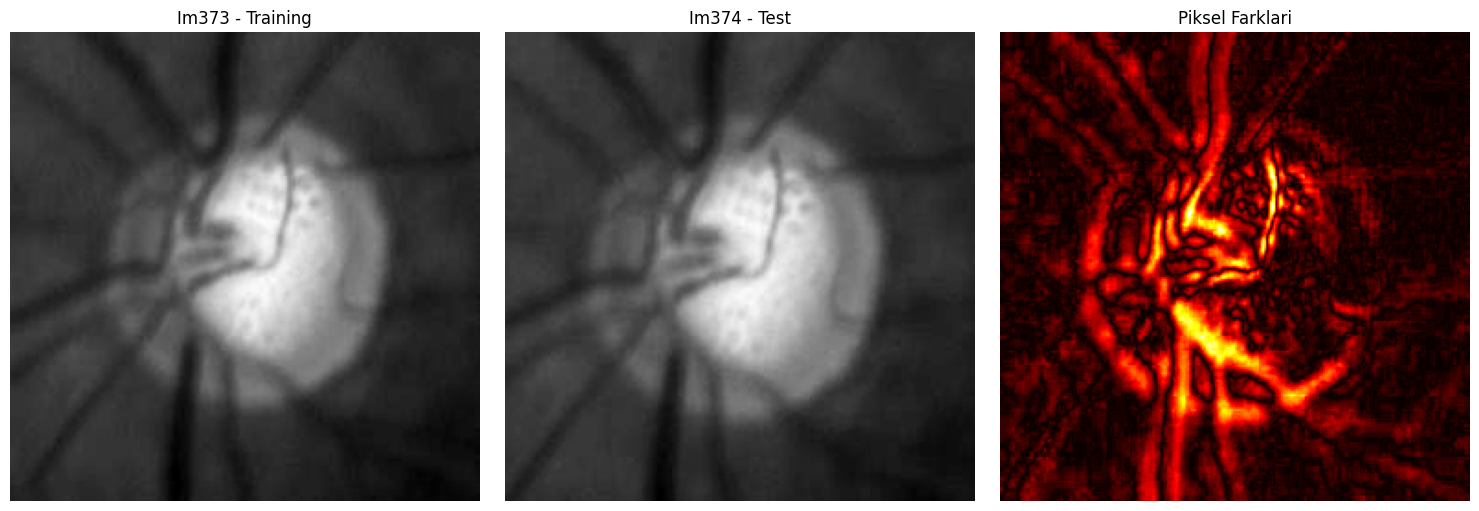

Ortalama mutlak piksel farkı: 4.52


In [24]:

import matplotlib.pyplot as plt
import numpy as np

# İki görüntü arasındaki mutlak fark
fark = np.abs(
    img1.astype(np.float32) -
    img2.astype(np.float32)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img1, cmap="gray")
axes[0].set_title("Im373 - Training")
axes[0].axis("off")

axes[1].imshow(img2, cmap="gray")
axes[1].set_title("Im374 - Test")
axes[1].axis("off")

axes[2].imshow(fark, cmap="hot")
axes[2].set_title("Piksel Farklari")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Ortalama mutlak piksel farkı:", round(fark.mean(), 2))


In [25]:

import pandas as pd

supheli_kayit = pd.DataFrame([{
    "dosya1": "Im373_g_ACRIMA.jpg",
    "dosya2": "Im374_g_ACRIMA.jpg",
    "bolme1": "train",
    "bolme2": "test",
    "ssim": 0.8832,
    "mean_absolute_pixel_difference": 4.52,
    "phash_distance": 10,
    "durum": "Yuksek tekrar suphesi - dogrulama gerekli"
}])

rapor_yolu = ROOT / "results" / "suspected_duplicates.csv"

supheli_kayit.to_csv(
    rapor_yolu,
    index=False
)

print("Şüpheli tekrar raporu kaydedildi!")
print(supheli_kayit)


Şüpheli tekrar raporu kaydedildi!
               dosya1              dosya2 bolme1 bolme2    ssim  \
0  Im373_g_ACRIMA.jpg  Im374_g_ACRIMA.jpg  train   test  0.8832   

   mean_absolute_pixel_difference  phash_distance  \
0                            4.52              10   

                                       durum  
0  Yuksek tekrar suphesi - dogrulama gerekli  


In [26]:

from skimage.metrics import structural_similarity as ssim
from PIL import Image
import numpy as np
import pandas as pd

def goruntu_oku(ad):
    with Image.open(image_dir / ad) as img:
        return np.array(
            img.convert("L").resize((256, 256))
        )

sonuclar = []

for _, satir in benzer_df.iterrows():
    img1 = goruntu_oku(satir["dosya1"])
    img2 = goruntu_oku(satir["dosya2"])

    skor = ssim(img1, img2, data_range=255)

    sonuclar.append({
        "dosya1": satir["dosya1"],
        "dosya2": satir["dosya2"],
        "bolme1": satir["bolme1"],
        "bolme2": satir["bolme2"],
        "phash_distance": satir["phash_uzakligi"],
        "ssim": skor
    })

ssim_df = pd.DataFrame(sonuclar)

# En yüksek SSIM değerinden sırala
ssim_df = ssim_df.sort_values(
    by="ssim",
    ascending=False
).reset_index(drop=True)

# Sonuçları kaydet
ssim_df.to_csv(
    ROOT / "results" / "near_duplicate_ssim_results.csv",
    index=False
)

print("SSIM analizi tamamlandı!")
print(ssim_df.to_string(index=False))


SSIM analizi tamamlandı!
            dosya1             dosya2     bolme1     bolme2  phash_distance     ssim
Im373_g_ACRIMA.jpg Im374_g_ACRIMA.jpg      train       test              10 0.883160
Im313_g_ACRIMA.jpg Im527_g_ACRIMA.jpg      train validation              10 0.865543
Im534_g_ACRIMA.jpg Im362_g_ACRIMA.jpg      train       test              10 0.852054
Im505_g_ACRIMA.jpg Im561_g_ACRIMA.jpg      train validation              10 0.825776
Im590_g_ACRIMA.jpg Im580_g_ACRIMA.jpg      train       test              10 0.760169
Im503_g_ACRIMA.jpg Im705_g_ACRIMA.jpg      train       test               8 0.758783
Im313_g_ACRIMA.jpg Im523_g_ACRIMA.jpg      train       test              10 0.743724
  Im241_ACRIMA.jpg   Im250_ACRIMA.jpg      train       test              10 0.739847
  Im176_ACRIMA.jpg   Im086_ACRIMA.jpg      train       test              10 0.734177
Im679_g_ACRIMA.jpg   Im138_ACRIMA.jpg      train       test              10 0.727528
Im557_g_ACRIMA.jpg   Im016_ACRIMA.jpg   